In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
import talib

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, classification_report, confusion_matrix, precision_score
from sklearn.tree import export_text

#pd.options.display.float_format = '{:.3f}'.format

### Get data

In [2]:
TRADING_DAYS = 21
RFR = 0.05
tickers = ["FMTY14.MX"]
fmty_df = pd.DataFrame()

for ticker in tickers:
    #get ticker available daily data
    ticker_yf = yf.Ticker(ticker)
    ticker_data = ticker_yf.history(period="max", interval="1d")
    #format date
    ticker_data["date"] = pd.to_datetime(ticker_data.index, format="%Y-%m-%d")
    #define future growth periods
    growth_periods = [TRADING_DAYS * month for month in range(1, 13)]
    for days in growth_periods:
        period = "growth_"+str(days)+"_d"
        ticker_data[period] = ticker_data["Close"].shift(-days) / ticker_data["Close"]
    #pause
    #time.sleep(0.1)
    
    if fmty_df.empty:
        fmty_df = ticker_data
    else:
        fmty_df = pd.concat([fmty_df, ticker_data], ignore_index=True)

In [3]:
fmty_df = fmty_df.reset_index(drop=True)

In [4]:
fmty_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2999 entries, 0 to 2998
Data columns (total 20 columns):
 #   Column        Non-Null Count  Dtype                             
---  ------        --------------  -----                             
 0   Open          2999 non-null   float64                           
 1   High          2999 non-null   float64                           
 2   Low           2999 non-null   float64                           
 3   Close         2999 non-null   float64                           
 4   Volume        2999 non-null   int64                             
 5   Dividends     2999 non-null   float64                           
 6   Stock Splits  2999 non-null   float64                           
 7   date          2999 non-null   datetime64[s, America/Mexico_City]
 8   growth_21_d   2978 non-null   float64                           
 9   growth_42_d   2957 non-null   float64                           
 10  growth_63_d   2936 non-null   float64                      

In [5]:
fmty_df["Volume"] = fmty_df["Volume"].astype("float64")

In [6]:
fmty_df = fmty_df.drop(columns=["Stock Splits"])

In [7]:
fmty_df.head()

,Open,High,Low,Close,Volume,Dividends,date,growth_21_d,growth_42_d,growth_63_d,growth_84_d,growth_105_d,growth_126_d,growth_147_d,growth_168_d,growth_189_d,growth_210_d,growth_231_d,growth_252_d
0,5.882079,5.882079,5.882079,5.882079,1.0,0.0,2014-12-15 00:00:00-06:00,0.995045,1.003303,1.065235,1.072667,1.043667,1.058659,1.067909,1.066089,1.108733,1.098499,1.107649,1.084229
1,5.828649,5.833507,5.828649,5.833507,59293.0,0.0,2014-12-16 00:00:00-06:00,0.999167,1.010825,1.074105,1.081598,1.052357,1.058148,1.083584,1.074966,1.117965,1.100766,1.119496,1.102003
2,5.828650,5.901508,5.828650,5.901508,82187.0,0.0,2014-12-17 00:00:00-06:00,0.987654,1.000000,1.061728,1.069135,1.040231,1.045955,1.071098,1.049829,1.105083,1.071080,1.110918,1.115241
3,5.901507,5.901507,5.877222,5.877222,118002.0,0.0,2014-12-18 00:00:00-06:00,0.991736,1.033058,1.064463,1.073553,1.045358,1.050277,1.075524,1.054167,1.101967,1.092578,1.115509,1.119850
4,6.042366,6.042366,5.877222,5.877222,17091.0,0.0,2014-12-19 00:00:00-06:00,0.991736,1.033058,1.057025,1.072728,1.060376,1.050277,1.075524,1.054167,1.097699,1.092578,1.115509,1.093806


In [8]:
fmty_df.shape

(2999, 19)

In [9]:
fmty_df[fmty_df.duplicated(keep="first")]

,Open,High,Low,Close,Volume,Dividends,date,growth_21_d,growth_42_d,growth_63_d,growth_84_d,growth_105_d,growth_126_d,growth_147_d,growth_168_d,growth_189_d,growth_210_d,growth_231_d,growth_252_d


In [10]:
fmty_df.shape

(2999, 19)

In [11]:
fmty_df.isnull().sum()

Open              0
High              0
Low               0
Close             0
Volume            0
Dividends         0
date              0
growth_21_d      21
growth_42_d      42
growth_63_d      63
growth_84_d      84
growth_105_d    105
growth_126_d    126
growth_147_d    147
growth_168_d    168
growth_189_d    189
growth_210_d    210
growth_231_d    231
growth_252_d    252
dtype: int64

In [12]:
#remove when all column values are NaN or missing, otherwise keep them
fmty_df = fmty_df.dropna(how="all")
fmty_df.shape

(2999, 19)

### Create desired indicators (month/quarter)

In [13]:
#list of momentum indicators to get
momentum_indicators = [
    "adx", "adxr", "apo", "aroonosc", "bop", "cci", "cmo", "dx",
    "macd", "mfi", "minus_di", "mom", "plus_di", "plus_dm", "ppo",
    "roc", "rocp", "rocr", "rocr100", "rsi", "trix", "ultosc", "willr"
]
#list of volume indicators to get
volume_indicators = ["ad", "adosc"]
#list of volatility indicators to get
volatility_indicators = ["atr", "natr"]
#list of cycle indicators to get
cycle_indicators = [
    "ht_dcperiod", "ht_dcphase", "ht_sine", "ht_leadsine", "ht_trendmod"
]
#list of price transforms indicators
price_indicators = ["avgprice", "medprice", "wclprice"]

In [14]:
#required features to get indicators
openn = fmty_df["Open"].values
close = fmty_df["Close"].values
high = fmty_df["High"].values
low = fmty_df["Low"].values
vol = fmty_df["Volume"].values

In [15]:
#momentum
fmty_df["adx_21"] = talib.ADX(high, low, close, timeperiod=TRADING_DAYS)
fmty_df["adxr_21"] = talib.ADXR(high, low, close, timeperiod=TRADING_DAYS)
fmty_df["apo_21_63"] = talib.APO(
    close, fastperiod=TRADING_DAYS, slowperiod=TRADING_DAYS * 3, matype=1
)
fmty_df["aroonosc_21"] = talib.AROONOSC(high, low, timeperiod=TRADING_DAYS)
fmty_df["aroonosc_63"] = talib.AROONOSC(high, low, timeperiod=TRADING_DAYS * 3)
fmty_df["bop"] = talib.BOP(openn, high, low, close)
fmty_df["cci_21"] = talib.CCI(high, low, close, timeperiod=TRADING_DAYS)
fmty_df["cmo_21"] = talib.CMO(close, timeperiod=TRADING_DAYS)
fmty_df["dx_21"] = talib.DX(high, low, close, timeperiod=TRADING_DAYS)
fmty_df["cci_63"] = talib.CCI(high, low, close, timeperiod=TRADING_DAYS * 3)
fmty_df["cmo_63"] = talib.CMO(close, timeperiod=TRADING_DAYS * 3)
fmty_df["dx_63"] = talib.DX(high, low, close, timeperiod=TRADING_DAYS * 3)
fmty_df["macd_21"], fmty_df["macd_sig_21"], fmty_df["macd_hist_21"] = talib.MACD(
    close, fastperiod=TRADING_DAYS, slowperiod=TRADING_DAYS * 3, signalperiod=TRADING_DAYS
)
fmty_df["macd_42"], fmty_df["macd_sig_42"], fmty_df["macd_hist_42"] = talib.MACD(
    close, fastperiod=TRADING_DAYS * 2, slowperiod=TRADING_DAYS * 6, signalperiod=TRADING_DAYS
)
fmty_df["mfi_21"] = talib.MFI(high, low, close, vol, timeperiod=TRADING_DAYS)
fmty_df["minus_di_21"] = talib.MINUS_DI(high, low, close, timeperiod=TRADING_DAYS)
fmty_df["mom_21"] = talib.MOM(close, timeperiod=TRADING_DAYS)
fmty_df["plus_di_21"] = talib.PLUS_DI(high, low, close, timeperiod=TRADING_DAYS)
fmty_df["plus_dm_21"] = talib.PLUS_DM(high, low, timeperiod=TRADING_DAYS)
fmty_df["mfi_63"] = talib.MFI(high, low, close, vol, timeperiod=TRADING_DAYS * 3)
fmty_df["minus_di_63"] = talib.MINUS_DI(high, low, close, timeperiod=TRADING_DAYS * 3)
fmty_df["mom_63"] = talib.MOM(close, timeperiod=TRADING_DAYS * 3)
fmty_df["plus_di_63"] = talib.PLUS_DI(high, low, close, timeperiod=TRADING_DAYS * 3)
fmty_df["plus_dm_63"] = talib.PLUS_DM(high, low, timeperiod=TRADING_DAYS * 3)
fmty_df["ppo_21_63"] = talib.PPO(close, fastperiod=TRADING_DAYS, slowperiod=TRADING_DAYS * 3, matype=1)
fmty_df["ppo_42_126"] = talib.PPO(close, fastperiod=TRADING_DAYS * 2, slowperiod=TRADING_DAYS * 6, matype=1)
fmty_df["roc_21"] = talib.ROC(close, timeperiod=TRADING_DAYS)
fmty_df["rocp_21"] = talib.ROCP(close, timeperiod=TRADING_DAYS)
fmty_df["rocr_21"] = talib.ROCR(close, timeperiod=TRADING_DAYS)
fmty_df["rocr100_21"] = talib.ROCR100(close, timeperiod=TRADING_DAYS)
fmty_df["rsi_21"] = talib.RSI(close, timeperiod=TRADING_DAYS)
fmty_df["trix_21"] = talib.TRIX(close, timeperiod=TRADING_DAYS)
fmty_df["roc_63"] = talib.ROC(close, timeperiod=TRADING_DAYS * 3)
fmty_df["rocp_63"] = talib.ROCP(close, timeperiod=TRADING_DAYS * 3)
fmty_df["rocr_63"] = talib.ROCR(close, timeperiod=TRADING_DAYS * 3)
fmty_df["rocr100_63"] = talib.ROCR100(close, timeperiod=TRADING_DAYS * 3)
fmty_df["rsi_63"] = talib.RSI(close, timeperiod=TRADING_DAYS * 3)
fmty_df["trix_63"] = talib.TRIX(close, timeperiod=TRADING_DAYS * 3)
fmty_df["ultosc_21"] = talib.ULTOSC(
    high, low, close, timeperiod1=TRADING_DAYS, timeperiod2=TRADING_DAYS * 2, timeperiod3=TRADING_DAYS * 4
)
fmty_df["ultosc_63"] = talib.ULTOSC(
    high, low, close, timeperiod1=TRADING_DAYS, timeperiod2=TRADING_DAYS * 3, timeperiod3=TRADING_DAYS * 6
)
fmty_df["willr_21"] = talib.WILLR(high, low, close, timeperiod=TRADING_DAYS)
fmty_df["willr_63"] = talib.WILLR(high, low, close, timeperiod=TRADING_DAYS * 3)

In [16]:
#volume
fmty_df["ad"] = talib.AD(high, low, close, vol)
fmty_df["adosc_21"] = talib.ADOSC(high, low, close, vol, fastperiod=TRADING_DAYS, slowperiod=TRADING_DAYS * 3)
fmty_df["adosc_63"] = talib.ADOSC(high, low, close, vol, fastperiod=TRADING_DAYS * 2, slowperiod=TRADING_DAYS * 6)
#volatility
fmty_df["atr_21"] = talib.ATR(high, low, close, timeperiod=TRADING_DAYS)
fmty_df["natr_21"] = talib.NATR(high, low, close, timeperiod=TRADING_DAYS)
fmty_df["natr_63"] = talib.NATR(high, low, close, timeperiod=TRADING_DAYS * 3)
#no params needed
fmty_df["ht_dcperiod"] = talib.HT_DCPERIOD(close)
fmty_df["ht_dcphase"] = talib.HT_DCPHASE(close)
fmty_df["ht_sine"], fmty_df["ht_leadsine"] = talib.HT_SINE(close)
fmty_df["ht_trendmod"]  = talib.HT_TRENDMODE(close)
#no params needed
fmty_df["avgprice"] = talib.AVGPRICE(openn, high, low, close)
fmty_df["medprice"] = talib.MEDPRICE(high, low)
fmty_df["wclprice"] = talib.WCLPRICE(high, low, close)

In [17]:
#other
fmty_df["volatility"] = fmty_df["Close"].rolling(30).std() * np.sqrt(252)
fmty_df["sharpe"] = (fmty_df["growth_252_d"] - RFR) / fmty_df["volatility"]

### Define to_predict

In [18]:
#quarterly growth
fmty_df["is_growth_63"] = (fmty_df.growth_63_d > 1).astype(int)
#fmty_df["is_growth_252"] = (fmty_df.growth_252_d > 1).astype(int)

In [19]:
print(fmty_df.info())

<class 'pandas.DataFrame'>
RangeIndex: 2999 entries, 0 to 2998
Data columns (total 82 columns):
 #   Column        Non-Null Count  Dtype                             
---  ------        --------------  -----                             
 0   Open          2999 non-null   float64                           
 1   High          2999 non-null   float64                           
 2   Low           2999 non-null   float64                           
 3   Close         2999 non-null   float64                           
 4   Volume        2999 non-null   float64                           
 5   Dividends     2999 non-null   float64                           
 6   date          2999 non-null   datetime64[s, America/Mexico_City]
 7   growth_21_d   2978 non-null   float64                           
 8   growth_42_d   2957 non-null   float64                           
 9   growth_63_d   2936 non-null   float64                           
 10  growth_84_d   2915 non-null   float64                      

In [20]:
fmty_df_stats = fmty_df[[f"growth_{str(TRADING_DAYS * month)}_d" for month in range(1, 13)]].describe()
fmty_df_stats

,growth_21_d,growth_42_d,growth_63_d,growth_84_d,growth_105_d,growth_126_d,growth_147_d,growth_168_d,growth_189_d,growth_210_d,growth_231_d,growth_252_d
count,2978.000000,2957.000000,2936.000000,2915.000000,2894.000000,2873.000000,2852.000000,2831.000000,2810.000000,2789.000000,2768.000000,2747.000000
mean,1.007898,1.015001,1.021892,1.029083,1.036339,1.043309,1.050981,1.059123,1.066919,1.074507,1.082748,1.090379
std,0.045824,0.060618,0.071300,0.084054,0.094505,0.102543,0.111304,0.123813,0.132114,0.141412,0.151427,0.159407
min,0.700000,0.705259,0.697017,0.692968,0.687265,0.679906,0.702760,0.706321,0.708716,0.705725,0.706321,0.714163
25%,0.986953,0.986558,0.987470,0.987448,0.986519,0.987603,0.983799,0.979166,0.976691,0.978954,0.981606,0.980101
50%,1.004189,1.012658,1.020505,1.030117,1.035669,1.037247,1.042964,1.047812,1.052908,1.055845,1.063939,1.070880
75%,1.024773,1.040674,1.054616,1.069774,1.082757,1.094834,1.104644,1.113326,1.120744,1.128308,1.135546,1.140831
max,1.263285,1.246957,1.315312,1.384217,1.370209,1.406363,1.456224,1.497598,1.500666,1.593774,1.631068,1.632858


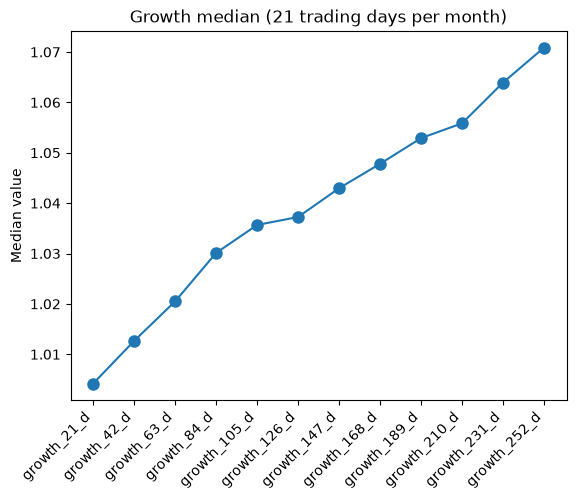

In [21]:
fig, ax = plt.subplots()

ax.plot(
    fmty_df_stats.loc["50%"].index, 
    fmty_df_stats.loc["50%"].values,
    marker="o",
    markersize=8
)

ax.set_ylabel("Median value")
ax.set_title("Growth median (21 trading days per month)")
ax.tick_params(axis="x", labelrotation=45)
plt.setp(ax.get_xticklabels(), ha="right")

plt.show()

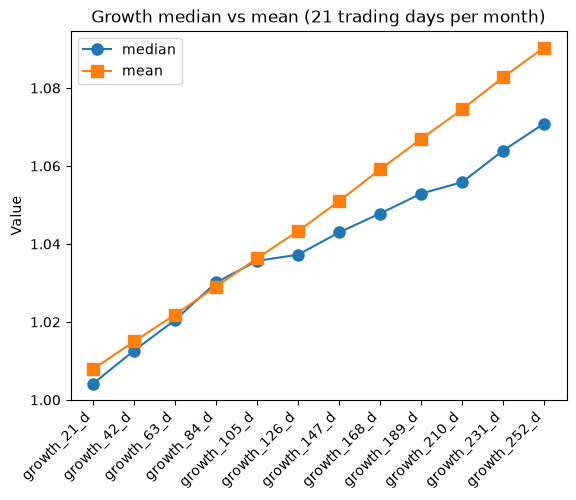

In [22]:
fig, ax = plt.subplots()

ax.plot(
    fmty_df_stats.loc["50%"].index, 
    fmty_df_stats.loc["50%"].values,
    marker="o",
    markersize=8,
    label="median"
)

ax.plot(
    fmty_df_stats.loc["mean"].index, 
    fmty_df_stats.loc["mean"].values,
    marker="s",
    markersize=8,
    label="mean"
)

ax.set_ylabel("Value")
ax.set_title("Growth median vs mean (21 trading days per month)")
ax.tick_params(axis="x", labelrotation=45)
plt.setp(ax.get_xticklabels(), ha="right")

ax.legend()
plt.show()

### Prepare features for dummies

In [23]:
#get wom from date
fmty_df["wom"] = fmty_df.date.dt.day.apply(
    lambda day : str((day - 1) // 7 + 1)
)

fmty_df[["date", "wom"]].head()

,date,wom
0,2014-12-15 00:00:00-06:00,3
1,2014-12-16 00:00:00-06:00,3
2,2014-12-17 00:00:00-06:00,3
3,2014-12-18 00:00:00-06:00,3
4,2014-12-19 00:00:00-06:00,3


In [24]:
#use month name from date
fmty_df["month"] = fmty_df["date"].dt.strftime("%b").str.lower()

fmty_df[["date", "month"]].head()

,date,month
0,2014-12-15 00:00:00-06:00,dec
1,2014-12-16 00:00:00-06:00,dec
2,2014-12-17 00:00:00-06:00,dec
3,2014-12-18 00:00:00-06:00,dec
4,2014-12-19 00:00:00-06:00,dec


In [25]:
#define new feature month_wom
fmty_df["month_wom"] = fmty_df["month"] + "_w" + fmty_df["wom"]

fmty_df[["month", "wom", "month_wom"]].head()

,month,wom,month_wom
0,dec,3,dec_w3
1,dec,3,dec_w3
2,dec,3,dec_w3
3,dec,3,dec_w3
4,dec,3,dec_w3


In [26]:
#define day of week from date
fmty_df["dow"] = fmty_df["date"].dt.strftime("%a").str.lower()

fmty_df[["date", "dow"]].head()

,date,dow
0,2014-12-15 00:00:00-06:00,mon
1,2014-12-16 00:00:00-06:00,tue
2,2014-12-17 00:00:00-06:00,wed
3,2014-12-18 00:00:00-06:00,thu
4,2014-12-19 00:00:00-06:00,fri


In [27]:
#remove aux column wom
fmty_df = fmty_df.drop(columns=["wom"])

fmty_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2999 entries, 0 to 2998
Data columns (total 85 columns):
 #   Column        Non-Null Count  Dtype                             
---  ------        --------------  -----                             
 0   Open          2999 non-null   float64                           
 1   High          2999 non-null   float64                           
 2   Low           2999 non-null   float64                           
 3   Close         2999 non-null   float64                           
 4   Volume        2999 non-null   float64                           
 5   Dividends     2999 non-null   float64                           
 6   date          2999 non-null   datetime64[s, America/Mexico_City]
 7   growth_21_d   2978 non-null   float64                           
 8   growth_42_d   2957 non-null   float64                           
 9   growth_63_d   2936 non-null   float64                           
 10  growth_84_d   2915 non-null   float64                      

In [28]:
fmty_df["ht_trendmod"] = fmty_df["ht_trendmod"].astype("float64")

In [29]:
print(fmty_df.info())

<class 'pandas.DataFrame'>
RangeIndex: 2999 entries, 0 to 2998
Data columns (total 85 columns):
 #   Column        Non-Null Count  Dtype                             
---  ------        --------------  -----                             
 0   Open          2999 non-null   float64                           
 1   High          2999 non-null   float64                           
 2   Low           2999 non-null   float64                           
 3   Close         2999 non-null   float64                           
 4   Volume        2999 non-null   float64                           
 5   Dividends     2999 non-null   float64                           
 6   date          2999 non-null   datetime64[s, America/Mexico_City]
 7   growth_21_d   2978 non-null   float64                           
 8   growth_42_d   2957 non-null   float64                           
 9   growth_63_d   2936 non-null   float64                           
 10  growth_84_d   2915 non-null   float64                      

In [30]:
#categorical features
CAT = ["month", "dow", "month_wom"]
#get dummies from CAT
dummies = pd.get_dummies(fmty_df[CAT], dtype="int32")
#concat fmty_df with ummies
fmty_w_dms = pd.concat([fmty_df, dummies], axis=1)

In [31]:
fmty_w_dms.info()

<class 'pandas.DataFrame'>
RangeIndex: 2999 entries, 0 to 2998
Columns: 162 entries, Open to month_wom_sep_w5
dtypes: datetime64[s, America/Mexico_City](1), float64(80), int32(77), int64(1), str(3)
memory usage: 2.9 MB


In [32]:
fmty_w_dms.columns.to_list()

['Open',
 'High',
 'Low',
 'Close',
 'Volume',
 'Dividends',
 'date',
 'growth_21_d',
 'growth_42_d',
 'growth_63_d',
 'growth_84_d',
 'growth_105_d',
 'growth_126_d',
 'growth_147_d',
 'growth_168_d',
 'growth_189_d',
 'growth_210_d',
 'growth_231_d',
 'growth_252_d',
 'adx_21',
 'adxr_21',
 'apo_21_63',
 'aroonosc_21',
 'aroonosc_63',
 'bop',
 'cci_21',
 'cmo_21',
 'dx_21',
 'cci_63',
 'cmo_63',
 'dx_63',
 'macd_21',
 'macd_sig_21',
 'macd_hist_21',
 'macd_42',
 'macd_sig_42',
 'macd_hist_42',
 'mfi_21',
 'minus_di_21',
 'mom_21',
 'plus_di_21',
 'plus_dm_21',
 'mfi_63',
 'minus_di_63',
 'mom_63',
 'plus_di_63',
 'plus_dm_63',
 'ppo_21_63',
 'ppo_42_126',
 'roc_21',
 'rocp_21',
 'rocr_21',
 'rocr100_21',
 'rsi_21',
 'trix_21',
 'roc_63',
 'rocp_63',
 'rocr_63',
 'rocr100_63',
 'rsi_63',
 'trix_63',
 'ultosc_21',
 'ultosc_63',
 'willr_21',
 'willr_63',
 'ad',
 'adosc_21',
 'adosc_63',
 'atr_21',
 'natr_21',
 'natr_63',
 'ht_dcperiod',
 'ht_dcphase',
 'ht_sine',
 'ht_leadsine',
 'ht_tr

### Correlation analysis

In [33]:
TARGET = "is_growth_63"
num_features = fmty_w_dms.select_dtypes(
    include=[np.number]
).columns.tolist()

cat_features = []
with pd.option_context("future.infer_string", True):
    cat_features = fmty_w_dms.select_dtypes(
        include=["str"]
    ).columns.tolist()

other_features = []
with pd.option_context("future.infer_string", True):
    other_features = fmty_w_dms.select_dtypes(
        exclude=[np.number, "str"]
    ).columns.tolist()

print("features in df: ", fmty_w_dms.shape[1])
print("numerical_features: ", len(num_features))
print("categorical_features: ", len(cat_features))
print("other_features: ", len(other_features))

features in df:  162
numerical_features:  158
categorical_features:  3
other_features:  1


In [34]:
#correlation with is_growth_63
corr_res = fmty_w_dms[num_features].corr().sort_values(TARGET, ascending=False)
corr_res

,Open,High,Low,Close,Volume,Dividends,growth_21_d,growth_42_d,growth_63_d,growth_84_d,...,month_wom_oct_w1,month_wom_oct_w2,month_wom_oct_w3,month_wom_oct_w4,month_wom_oct_w5,month_wom_sep_w1,month_wom_sep_w2,month_wom_sep_w3,month_wom_sep_w4,month_wom_sep_w5
is_growth_63,-0.102108,-0.101087,-0.106462,-0.107200,0.005356,-0.003228,0.389487,0.535814,0.692732,0.610893,...,0.005752,0.007484,0.007484,-0.012379,-0.007943,0.052177,0.027348,0.017646,0.027348,0.022075
growth_63_d,0.032817,0.035114,0.028217,0.028538,0.012625,0.009972,0.541058,0.772620,1.000000,0.837173,...,0.035206,0.029558,0.028983,0.027596,0.023101,0.044037,0.028001,0.022559,0.036294,0.036330
growth_105_d,0.049211,0.052597,0.041863,0.043293,0.026268,0.020300,0.452985,0.643220,0.759171,0.871139,...,0.010580,0.015961,0.022288,0.005167,-0.006251,0.029273,0.000605,0.004604,0.023862,0.016726
growth_84_d,0.037562,0.040968,0.031379,0.032641,0.028088,0.017783,0.526753,0.691435,0.837173,1.000000,...,-0.000998,-0.000875,0.020526,0.028385,0.026964,0.065202,0.024710,0.010535,0.019743,0.019683
growth_126_d,0.059659,0.064229,0.052365,0.054280,0.025981,0.017115,0.376025,0.552529,0.698351,0.797359,...,-0.024873,-0.018156,-0.017640,-0.005725,-0.001911,0.040501,0.020866,0.002072,0.000966,0.010666
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
minus_di_21,-0.503593,-0.505529,-0.502705,-0.501187,-0.033376,-0.031387,-0.086659,-0.145329,-0.203542,-0.227816,...,-0.024880,-0.002520,-0.001487,0.007786,0.024246,-0.039487,-0.049246,-0.040776,-0.024804,-0.018039
month_mar,-0.008352,-0.007142,-0.008674,-0.008297,0.071809,0.021869,-0.114848,-0.067659,-0.099509,-0.060765,...,-0.042534,-0.042900,-0.042900,-0.042900,-0.027528,-0.042900,-0.042900,-0.039491,-0.042900,-0.023331
ultosc_21,-0.294567,-0.295197,-0.288677,-0.284708,-0.046193,-0.017419,-0.168014,-0.231654,-0.262683,-0.289135,...,0.029725,0.026511,-0.001719,0.006776,0.007830,-0.070081,-0.039902,-0.015387,0.002223,0.008088
ultosc_63,-0.293121,-0.293827,-0.287222,-0.283249,-0.045207,-0.020913,-0.167055,-0.234347,-0.264779,-0.297059,...,0.031482,0.024984,-0.003041,-0.000357,0.000413,-0.065436,-0.034442,-0.011086,0.006596,0.009325


In [35]:
#select target variable to apply month_wom filter
corr_res_df = corr_res[TARGET].copy()
#use index as column
corr_res_df_tg = corr_res_df.reset_index()
#rename columns, use abs_corr to save corr value
corr_res_df_tg.columns = ["dummy_feature", "corr_val"]
#filter month_wom features
month_wom_filter = corr_res_df_tg[corr_res_df_tg["dummy_feature"].str.contains("month_wom")]
#round to 3 decimal places
month_wom_filter["corr_val"] = month_wom_filter["corr_val"].round(3)
month_wom_filter.head()

,dummy_feature,corr_val
21,month_wom_aug_w1,0.077
27,month_wom_jun_w3,0.062
32,month_wom_jun_w4,0.057
37,month_wom_sep_w1,0.052
38,month_wom_aug_w4,0.052


month_wom correlation is higher at end of Q2 and mid-end Q3

### Data Splits

In [36]:
#code frommodule 3 notebook
def get_splits(df, min_date, max_date, train_sz=0.7, val_sz=0.15):
    """
    Create a 'split' column with train, validation and test labels.
    Args:
        df (DataFrame): A Dataframe, sorted by sequence/time before call
        min_date: minimum date to start
        max_date: max date to stop
        train (float): Proportion of data for training
        val (float): Proportion of data for validation
    Returns:
        split_labels: column "split" indicating label for each row
    """

    train_end = min_date + pd.Timedelta(days=(max_date - min_date).days * train_sz)
    val_end = train_end + pd.Timedelta(days=(max_date - min_date).days * val_sz)
    
    split_labels = []
    for date in df["date"]:
        if date <= train_end:
            split_labels.append("train")
        elif date <= val_end:
            split_labels.append("val")
        else:
            split_labels.append("test")

    return split_labels

In [37]:
#get splits
fmty_w_dms["split"] = get_splits(
    fmty_w_dms,
    min_date = fmty_w_dms.date.min(),
    max_date = fmty_w_dms.date.max()
)
#split proportion
fmty_w_dms["split"].value_counts() / len(fmty_w_dms)

split
train    0.700567
test     0.150050
val      0.149383
Name: count, dtype: float64

In [38]:
fmty_w_dms.groupby(["split"])["date"].agg({"min", "max", "count"})

,min,count,max
split,,,
test,2025-02-04 00:00:00-06:00,450,2026-11-19 00:00:00-06:00
train,2014-12-15 00:00:00-06:00,2101,2023-04-21 00:00:00-06:00
val,2023-04-24 00:00:00-06:00,448,2025-01-31 00:00:00-06:00


### Hand Rules

In [39]:
#indicators to choose from to define hand rules
selected_indicators = [
    "cci_21", "cci_63", "cmo_21", "cmo_63", "adosc_21", "adosc_63", "medprice", "wclprice"
]

fmty_w_dms[selected_indicators].describe()

,cci_21,cci_63,cmo_21,cmo_63,adosc_21,adosc_63,medprice,wclprice
count,2979.000000,2937.000000,2978.000000,2936.000000,2.937000e+03,2.874000e+03,2999.000000,2999.000000
mean,15.416332,32.195448,4.875620,4.500750,1.714571e+06,3.088764e+06,8.372774,8.372610
std,111.883917,120.610095,17.970070,10.147665,1.402731e+07,1.855012e+07,2.345080,2.342557
min,-329.935909,-784.582639,-76.912417,-49.944037,-2.976374e+07,-2.377842e+07,4.948917,4.932490
25%,-64.272068,-47.203826,-6.302998,-2.279032,-8.336037e+05,-1.964873e+06,6.893379,6.899737
50%,18.266726,42.409580,4.647376,5.245570,2.045866e+05,3.766520e+05,7.377468,7.392164
75%,92.027278,106.292993,15.298436,11.392691,7.149858e+05,1.359068e+06,9.062505,9.055146
max,640.624572,975.889083,71.766988,37.895162,1.272881e+08,1.231234e+08,16.445000,16.462500


In [40]:
#create hand rules
#−100 to +100 price is in its "normal" range
fmty_w_dms["rl_0_cci_63"] = ((fmty_w_dms.cci_63 > -110) & (fmty_w_dms.cci_63 < 105)).astype(int)
#−50 to +50 price is in its "normal" range
fmty_w_dms["rl_1_cmo_63"] = ((fmty_w_dms.cmo_63 > -50) & (fmty_w_dms.cmo_63 < 50)).astype(int)
#adosc > 0 buy accelerates, adosc < 0 sell accelerates, ~0 balanced
fmty_w_dms["rl_2_cci_adosc_63"] = (
    (fmty_w_dms.cci_63 > -120) & (fmty_w_dms.cci_63 < 100) & (fmty_w_dms.adosc_63 > 0)
).astype(int)
fmty_w_dms["rl_3_cmo_adosc_63"] = (
    (fmty_w_dms.cci_63 > -50) & (fmty_w_dms.cci_63 < 50) & (fmty_w_dms.adosc_63 > 0)
).astype(int)

In [41]:
fmty_w_dms.groupby(by="split")[TARGET].describe()

,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
test,450.0,0.648889,0.477849,0.0,0.0,1.0,1.0,1.0
train,2101.0,0.652070,0.476427,0.0,0.0,1.0,1.0,1.0
val,448.0,0.584821,0.493304,0.0,0.0,1.0,1.0,1.0


In [42]:
#rules
RULES = [pred_name for pred_name in fmty_w_dms.keys() if pred_name.startswith("rl")]
RULES

['rl_0_cci_63', 'rl_1_cmo_63', 'rl_2_cci_adosc_63', 'rl_3_cmo_adosc_63']

In [43]:
#create column is_correct from each rule
for rule in RULES:
    prefix = rule.split("_")[1]
    fmty_w_dms[f"is_correct_{prefix}"] = (
        fmty_w_dms[rule] == fmty_w_dms[TARGET]
    ).astype(int)

In [44]:
#list of is_correct names
IS_CORRECT = [name for name in fmty_w_dms.keys() if name.startswith("is_correct")]
IS_CORRECT

['is_correct_0', 'is_correct_1', 'is_correct_2', 'is_correct_3']

In [45]:
fmty_w_dms[RULES].describe()

,rl_0_cci_63,rl_1_cmo_63,rl_2_cci_adosc_63,rl_3_cmo_adosc_63
count,2999.000000,2999.000000,2999.000000,2999.000000
mean,0.610203,0.978993,0.342447,0.171057
std,0.487785,0.143431,0.474608,0.376622
min,0.000000,0.000000,0.000000,0.000000
25%,0.000000,1.000000,0.000000,0.000000
50%,1.000000,1.000000,0.000000,0.000000
75%,1.000000,1.000000,1.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000


In [46]:
fmty_w_dms[IS_CORRECT].describe()

,is_correct_0,is_correct_1,is_correct_2,is_correct_3
count,2999.000000,2999.000000,2999.000000,2999.000000
mean,0.559186,0.623208,0.370790,0.352784
std,0.496567,0.484663,0.483097,0.477916
min,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000
50%,1.000000,1.000000,0.000000,0.000000
75%,1.000000,1.000000,1.000000,1.000000
max,1.000000,1.000000,1.000000,1.000000


In [47]:
#code from module 3 notebook
for idx, col in enumerate(IS_CORRECT):
  #define precision for predictions on a test dataset
  rule = RULES[idx]
  rule_correct = col
  rule_filter = ((fmty_w_dms.split == "test") & (fmty_w_dms[rule] == 1))

  print(f"rule:{rule}, rule_correct:{rule_correct}")
  print("Counts:",fmty_w_dms[rule_filter][rule_correct].value_counts())
  print("--")
  print("Ratio:",(fmty_w_dms[rule_filter][rule_correct].value_counts() / len(fmty_w_dms[rule_filter])).round(3))

  print("------")

rule:rl_0_cci_63, rule_correct:is_correct_0
Counts: is_correct_0
1    185
0    104
Name: count, dtype: int64
--
Ratio: is_correct_0
1    0.64
0    0.36
Name: count, dtype: float64
------
rule:rl_1_cmo_63, rule_correct:is_correct_1
Counts: is_correct_1
1    292
0    158
Name: count, dtype: int64
--
Ratio: is_correct_1
1    0.649
0    0.351
Name: count, dtype: float64
------
rule:rl_2_cci_adosc_63, rule_correct:is_correct_2
Counts: is_correct_2
0    90
1    53
Name: count, dtype: int64
--
Ratio: is_correct_2
0    0.629
1    0.371
Name: count, dtype: float64
------
rule:rl_3_cmo_adosc_63, rule_correct:is_correct_3
Counts: is_correct_3
0    62
1    18
Name: count, dtype: int64
--
Ratio: is_correct_3
0    0.775
1    0.225
Name: count, dtype: float64
------


In [48]:
#precision
for rule in RULES:
    target = fmty_w_dms[fmty_w_dms["split"] == "test"][TARGET]
    pred = fmty_w_dms[fmty_w_dms["split"] == "test"][rule]

    tp = ((pred == 1) & (pred == target)).sum()
    fp = ((pred == 1) & (pred != target)).sum()

    #using tp, fp
    precision = tp / (tp + fp)

    print(f"\nRule:{rule} \nprecision (tp, fp):{np.round(precision, 3)}")
    #from precision_score
    #print("prec_score:", np.round(precision_score(target, pred), 3))


Rule:rl_0_cci_63 
precision (tp, fp):0.64

Rule:rl_1_cmo_63 
precision (tp, fp):0.649

Rule:rl_2_cci_adosc_63 
precision (tp, fp):0.371

Rule:rl_3_cmo_adosc_63 
precision (tp, fp):0.225


### Modeling

#### Decision Tree Classifier

In [49]:
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    print(fmty_w_dms.isnull().sum())

Open                   0
High                   0
Low                    0
Close                  0
Volume                 0
Dividends              0
date                   0
growth_21_d           21
growth_42_d           42
growth_63_d           63
growth_84_d           84
growth_105_d         105
growth_126_d         126
growth_147_d         147
growth_168_d         168
growth_189_d         189
growth_210_d         210
growth_231_d         231
growth_252_d         252
adx_21                41
adxr_21               61
apo_21_63             62
aroonosc_21           21
aroonosc_63           63
bop                    0
cci_21                20
cmo_21                21
dx_21                 21
cci_63                62
cmo_63                63
dx_63                 63
macd_21               82
macd_sig_21           82
macd_hist_21          82
macd_42              145
macd_sig_42          145
macd_hist_42         145
mfi_21                21
minus_di_21           21
mom_21                21


In [50]:
#fill missing values, 0 default
def replace_fill_missing(df:pd.DataFrame):
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df.fillna(0, inplace=True)
    return df

In [51]:
#select desired features
growth = [name for name in fmty_w_dms.keys() if name.startswith("growth")]
indicator_prefix = momentum_indicators + volume_indicators + volatility_indicators + cycle_indicators + price_indicators
indicators = [
    name for name in fmty_w_dms.keys() if any(
        name.startswith(prefix) for prefix in indicator_prefix
    )
]
dummy = dummies.columns.to_list()

#features = growth + indicators + dummy + [TARGET]
features = indicators + dummy + [TARGET]
len(features)

138

In [52]:
features

['adx_21',
 'adxr_21',
 'apo_21_63',
 'aroonosc_21',
 'aroonosc_63',
 'bop',
 'cci_21',
 'cmo_21',
 'dx_21',
 'cci_63',
 'cmo_63',
 'dx_63',
 'macd_21',
 'macd_sig_21',
 'macd_hist_21',
 'macd_42',
 'macd_sig_42',
 'macd_hist_42',
 'mfi_21',
 'minus_di_21',
 'mom_21',
 'plus_di_21',
 'plus_dm_21',
 'mfi_63',
 'minus_di_63',
 'mom_63',
 'plus_di_63',
 'plus_dm_63',
 'ppo_21_63',
 'ppo_42_126',
 'roc_21',
 'rocp_21',
 'rocr_21',
 'rocr100_21',
 'rsi_21',
 'trix_21',
 'roc_63',
 'rocp_63',
 'rocr_63',
 'rocr100_63',
 'rsi_63',
 'trix_63',
 'ultosc_21',
 'ultosc_63',
 'willr_21',
 'willr_63',
 'ad',
 'adosc_21',
 'adosc_63',
 'atr_21',
 'natr_21',
 'natr_63',
 'ht_dcperiod',
 'ht_dcphase',
 'ht_sine',
 'ht_leadsine',
 'ht_trendmod',
 'avgprice',
 'medprice',
 'wclprice',
 'month_apr',
 'month_aug',
 'month_dec',
 'month_feb',
 'month_jan',
 'month_jul',
 'month_jun',
 'month_mar',
 'month_may',
 'month_nov',
 'month_oct',
 'month_sep',
 'dow_fri',
 'dow_mon',
 'dow_thu',
 'dow_tue',
 'dow_

In [ ]:
#prepare data for model
train = fmty_w_dms[fmty_w_dms.split.isin(["train", "val"])].copy()
test = fmty_w_dms[fmty_w_dms.split.isin(["test"])].copy()

#define splits
x_train = train[features]
x_test = test[features]

#all splits
x_all = fmty_w_dms[features].copy()

print(f"length: x_train {x_train.shape}, x_test {x_test.shape}, x_all: x_all {x_all.shape}")

length: x_train (2549, 138), x_test (450, 138), x_all: x_all (2999, 138)


In [54]:
#replace missing
x_train = replace_fill_missing(x_train)
x_test = replace_fill_missing(x_test)
x_all = replace_fill_missing(x_all)
#isolate target
y_train = x_train[TARGET]
y_test = x_test[TARGET]
y_all = x_all[TARGET]
#remove target from features
del x_train[TARGET]
del x_test[TARGET]
del x_all[TARGET]
#remove original feature from features
#del x_train["growth_63_d"]
#del x_test["growth_63_d"]
#del x_all["growth_63_d"]

In [55]:
#estimate parameters for decision tree classifier
#start simple
param_gscv = {
    "max_depth": [2, 3, 5, 7, 10]
}

gscv_dtc = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_gscv,
    cv=4,
    n_jobs=1,
    scoring=make_scorer(precision_score, average="weighted", zero_division=0),
    #scoring=make_scorer(f1_score, average="weighted"),
    return_train_score=True
)

gscv_dtc.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [2, 3, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",make_scorer(p...ro_division=0)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",4
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``sc

In [56]:
print(f"Best params: {gscv_dtc.best_params_}")
print(f"Best CV score: {gscv_dtc.best_score_:.3f}")

Best params: {'max_depth': 2}
Best CV score: 0.747


In [57]:
y_pred_test_dtc = gscv_dtc.predict(x_test)
print(classification_report(y_test, y_pred_test_dtc))

              precision    recall  f1-score   support

           0       0.68      0.68      0.68       158
           1       0.83      0.83      0.83       292

    accuracy                           0.77       450
   macro avg       0.75      0.75      0.75       450
weighted avg       0.77      0.77      0.77       450



In [58]:
cm_dtc = confusion_matrix(y_test, y_pred_test_dtc)
print(cm_dtc)

[[107  51]
 [ 51 241]]


In [59]:
tree_dtc = gscv_dtc.best_estimator_
print(export_text(tree_dtc, feature_names=list(x_train.columns)))

|--- minus_di_63 <= 16.33
|   |--- month_mar <= 0.50
|   |   |--- class: 1
|   |--- month_mar >  0.50
|   |   |--- class: 1
|--- minus_di_63 >  16.33
|   |--- wclprice <= 6.92
|   |   |--- class: 1
|   |--- wclprice >  6.92
|   |   |--- class: 0



In [60]:
results_dtc = pd.DataFrame(gscv_dtc.cv_results_)
top_dtc = results_dtc.nsmallest(5, "rank_test_score")[["params", "mean_test_score"]]
print(top_dtc)

              params  mean_test_score
0   {'max_depth': 2}         0.747261
3   {'max_depth': 7}         0.581311
4  {'max_depth': 10}         0.542118
1   {'max_depth': 3}         0.541419
2   {'max_depth': 5}         0.498944


In [61]:
model_params_dtc = top_dtc.iloc[0]["params"]
model_params_dtc

{'max_depth': 2}

In [62]:
#set up decision tree classifier with your best selected params
dt_clf = DecisionTreeClassifier(**model_params_dtc, random_state=42)
#fit on training data only
dt_clf.fit(x_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

#### Random Forest Classifier

In [63]:
#estimate parameters for random forest classifier
param_gscv = {
    "n_estimators": [10, 30, 50, 100],
    "max_depth": [2, 3, 5, 7, 10]
}

gscv_rfc = GridSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=1),
    param_gscv,
    cv=4,
    n_jobs=1,
    scoring=make_scorer(precision_score, average="weighted", zero_division=0),
    #scoring=make_scorer(f1_score, average="weighted"),
    return_train_score=True
)

gscv_rfc.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [2, 3, ...], 'n_estimators': [10, 30, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",make_scorer(p...ro_division=0)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",4
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r

In [64]:
print(f"Best params: {gscv_rfc.best_params_}")
print(f"Best CV score: {gscv_rfc.best_score_:.3f}")

Best params: {'max_depth': 10, 'n_estimators': 30}
Best CV score: 0.666


In [65]:
y_pred_test_rfc = gscv_rfc.predict(x_test)
print(classification_report(y_test, y_pred_test_rfc))

              precision    recall  f1-score   support

           0       0.48      0.47      0.47       158
           1       0.72      0.73      0.72       292

    accuracy                           0.64       450
   macro avg       0.60      0.60      0.60       450
weighted avg       0.63      0.64      0.63       450



In [66]:
cm_rfc = confusion_matrix(y_test, y_pred_test_rfc)
print(cm_rfc)

[[ 74  84]
 [ 80 212]]


In [67]:
results_rfc = pd.DataFrame(gscv_rfc.cv_results_)
top_rfc = results_rfc.nsmallest(5, "rank_test_score")[["params", "mean_test_score"]]
print(top_rfc)

                                   params  mean_test_score
17  {'max_depth': 10, 'n_estimators': 30}         0.666142
18  {'max_depth': 10, 'n_estimators': 50}         0.664840
10   {'max_depth': 5, 'n_estimators': 50}         0.656870
8    {'max_depth': 5, 'n_estimators': 10}         0.653241
9    {'max_depth': 5, 'n_estimators': 30}         0.646507


In [68]:
model_params_rfc = top_rfc.iloc[0]["params"]
model_params_rfc

{'max_depth': 10, 'n_estimators': 30}

In [69]:
#set up random forest classifier with your best selected params
rf_clf = RandomForestClassifier(**model_params_rfc, random_state=42, n_jobs=1)
#fit on training data only
rf_clf.fit(x_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",30
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total num

### Use predict probabilities

#### DecisionTreeClassifier probabilities

In [70]:
#probability instead of label
y_pred_prob_dtc = dt_clf.predict_proba(x_test)
#prob[1] is the second element in the list of class predictions
y_pred_pos_class_dtc = [prob[1] for prob in y_pred_prob_dtc]

In [71]:
y_pred_pos_class_dtc_df = pd.DataFrame(y_pred_pos_class_dtc, columns=['prob_pos_class'])
y_pred_pos_class_dtc_df.sample(10)

,prob_pos_class
227,0.924357
207,0.924357
131,0.924357
60,0.924357
400,0.402027
160,0.924357
209,0.924357
367,0.402027
35,0.563636
318,0.402027


In [72]:
y_pred_pos_class_dtc_df.describe().T

,count,mean,std,min,25%,50%,75%,max
prob_pos_class,450.0,0.724929,0.248882,0.402027,0.402027,0.924357,0.924357,0.924357


In [73]:
#unconditional probability growth_63_d > 1
y_test.sum()/y_test.count()

np.float64(0.6488888888888888)

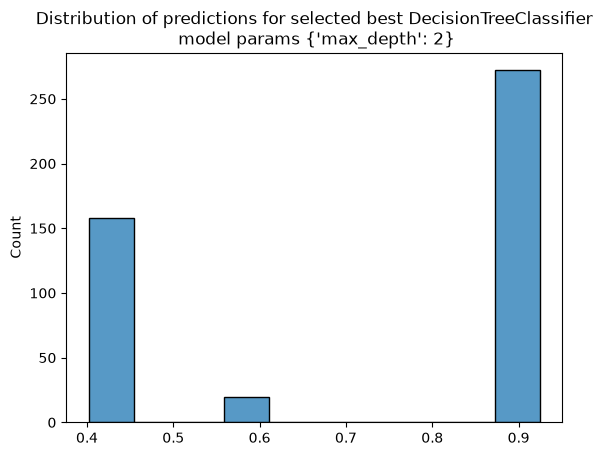

In [74]:
sns.histplot(y_pred_pos_class_dtc)
plt.title(f"Distribution of predictions for selected best DecisionTreeClassifier\n model params {model_params_dtc}")
plt.show()

In [75]:
def get_bin_threshold(y_true, y_pred, only_even=False):
    scores = []

    if only_even==False:
       #[0, 0.01, 0.02, ...0.99,1.0]
       thresholds = np.linspace(0, 1, 101)
    else:
       #[0, 0.02, 0.04,  ...0.98,1.0]
       thresholds = np.linspace(0, 1, 51)

    for t in thresholds:
        actual_positive = (y_true == 1)
        actual_negative = (y_true == 0)
        predict_positive = (y_pred >= t)
        predict_negative = (y_pred < t)

        tp = (predict_positive & actual_positive).sum()
        tn = (predict_negative & actual_negative).sum()
        fp = (predict_positive & actual_negative).sum()
        fn = (predict_negative & actual_positive).sum()

        if tp + fp > 0:
          precision = tp / (tp + fp)

        if tp + fn > 0:
          recall = tp / (tp + fn)

        if precision+recall > 0:
          f1_score = 2*precision*recall / (precision+recall)

        accuracy = (tp+tn) / (tp+tn+fp+fn)

        scores.append((t, tp, fp, fn, tn, precision, recall, accuracy, f1_score))

    columns = [
       "threshold", "tp", "fp", "fn", "tn",
       "precision", "recall", "accuracy", "f1_score"
    ]
    
    df_scores = pd.DataFrame(scores, columns=columns)
    df_scores["tpr"] = df_scores.tp / (df_scores.tp + df_scores.fn)
    df_scores["fpr"] = df_scores.fp / (df_scores.fp + df_scores.tn)

    return df_scores

In [76]:
df_scores_dtc = get_bin_threshold(y_test, y_pred_pos_class_dtc, only_even=True)
df_scores_dtc

,threshold,tp,fp,fn,tn,precision,recall,accuracy,f1_score,tpr,fpr
0,0.00,292,158,0,0,0.648889,1.000000,0.648889,0.787062,1.000000,1.000000
1,0.02,292,158,0,0,0.648889,1.000000,0.648889,0.787062,1.000000,1.000000
2,0.04,292,158,0,0,0.648889,1.000000,0.648889,0.787062,1.000000,1.000000
3,0.06,292,158,0,0,0.648889,1.000000,0.648889,0.787062,1.000000,1.000000
4,0.08,292,158,0,0,0.648889,1.000000,0.648889,0.787062,1.000000,1.000000
5,0.10,292,158,0,0,0.648889,1.000000,0.648889,0.787062,1.000000,1.000000
6,0.12,292,158,0,0,0.648889,1.000000,0.648889,0.787062,1.000000,1.000000
7,0.14,292,158,0,0,0.648889,1.000000,0.648889,0.787062,1.000000,1.000000
8,0.16,292,158,0,0,0.648889,1.000000,0.648889,0.787062,1.000000,1.000000
9,0.18,292,158,0,0,0.648889,1.000000,0.648889,0.787062,1.000000,1.000000


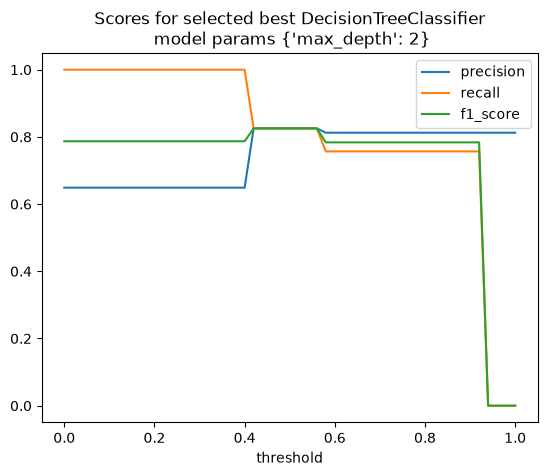

In [77]:
#try to find high precision score points
df_scores_dtc.plot.line(
    x="threshold",
    y=["precision", "recall", "f1_score"],
    title = f"Scores for selected best DecisionTreeClassifier\n model params {model_params_dtc}"
)
plt.show()

In [78]:
df_scores_dtc[(df_scores_dtc.threshold>0.42) & (df_scores_dtc.threshold<0.6)]

,threshold,tp,fp,fn,tn,precision,recall,accuracy,f1_score,tpr,fpr
22,0.44,241,51,51,107,0.825342,0.825342,0.773333,0.825342,0.825342,0.322785
23,0.46,241,51,51,107,0.825342,0.825342,0.773333,0.825342,0.825342,0.322785
24,0.48,241,51,51,107,0.825342,0.825342,0.773333,0.825342,0.825342,0.322785
25,0.50,241,51,51,107,0.825342,0.825342,0.773333,0.825342,0.825342,0.322785
26,0.52,241,51,51,107,0.825342,0.825342,0.773333,0.825342,0.825342,0.322785
27,0.54,241,51,51,107,0.825342,0.825342,0.773333,0.825342,0.825342,0.322785
28,0.56,241,51,51,107,0.825342,0.825342,0.773333,0.825342,0.825342,0.322785
29,0.58,221,51,71,107,0.812500,0.756849,0.728889,0.783688,0.756849,0.322785


In [79]:
df_scores_dtc[(df_scores_dtc.threshold>0.42)]

,threshold,tp,fp,fn,tn,precision,recall,accuracy,f1_score,tpr,fpr
22,0.44,241,51,51,107,0.825342,0.825342,0.773333,0.825342,0.825342,0.322785
23,0.46,241,51,51,107,0.825342,0.825342,0.773333,0.825342,0.825342,0.322785
24,0.48,241,51,51,107,0.825342,0.825342,0.773333,0.825342,0.825342,0.322785
25,0.50,241,51,51,107,0.825342,0.825342,0.773333,0.825342,0.825342,0.322785
26,0.52,241,51,51,107,0.825342,0.825342,0.773333,0.825342,0.825342,0.322785
27,0.54,241,51,51,107,0.825342,0.825342,0.773333,0.825342,0.825342,0.322785
28,0.56,241,51,51,107,0.825342,0.825342,0.773333,0.825342,0.825342,0.322785
29,0.58,221,51,71,107,0.812500,0.756849,0.728889,0.783688,0.756849,0.322785
30,0.60,221,51,71,107,0.812500,0.756849,0.728889,0.783688,0.756849,0.322785
31,0.62,221,51,71,107,0.812500,0.756849,0.728889,0.783688,0.756849,0.322785


In [80]:
df_scores_dtc[(df_scores_dtc.threshold>0.6)]

,threshold,tp,fp,fn,tn,precision,recall,accuracy,f1_score,tpr,fpr
31,0.62,221,51,71,107,0.8125,0.756849,0.728889,0.783688,0.756849,0.322785
32,0.64,221,51,71,107,0.8125,0.756849,0.728889,0.783688,0.756849,0.322785
33,0.66,221,51,71,107,0.8125,0.756849,0.728889,0.783688,0.756849,0.322785
34,0.68,221,51,71,107,0.8125,0.756849,0.728889,0.783688,0.756849,0.322785
35,0.70,221,51,71,107,0.8125,0.756849,0.728889,0.783688,0.756849,0.322785
36,0.72,221,51,71,107,0.8125,0.756849,0.728889,0.783688,0.756849,0.322785
37,0.74,221,51,71,107,0.8125,0.756849,0.728889,0.783688,0.756849,0.322785
38,0.76,221,51,71,107,0.8125,0.756849,0.728889,0.783688,0.756849,0.322785
39,0.78,221,51,71,107,0.8125,0.756849,0.728889,0.783688,0.756849,0.322785
40,0.80,221,51,71,107,0.8125,0.756849,0.728889,0.783688,0.756849,0.322785


#### RandomForestClassifier probabilities

In [81]:
#probability instead of label
y_pred_prob_rfc = rf_clf.predict_proba(x_test)
#prob[1] is the second element in the list of class predictions
y_pred_pos_class_rfc = [prob[1] for prob in y_pred_prob_rfc]

In [82]:
y_pred_pos_class_rfc_df = pd.DataFrame(y_pred_pos_class_rfc, columns=["prob_pos_class"])
y_pred_pos_class_rfc_df.sample(10)

,prob_pos_class
134,0.632890
427,0.476414
234,0.595924
353,0.502134
409,0.469116
363,0.692085
4,0.760868
54,0.492630
305,0.534009
420,0.448333


In [83]:
y_pred_pos_class_rfc_df.describe().T

,count,mean,std,min,25%,50%,75%,max
prob_pos_class,450.0,0.552542,0.113236,0.271743,0.47403,0.536188,0.62814,0.930075


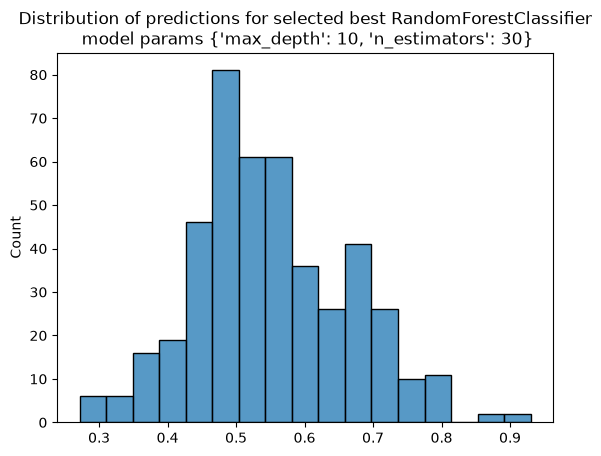

In [84]:
sns.histplot(y_pred_pos_class_rfc)
plt.title(f"Distribution of predictions for selected best RandomForestClassifier\n model params {model_params_rfc}")
plt.show()

In [85]:
df_scores_rfc = get_bin_threshold(y_test, y_pred_pos_class_rfc, only_even=True)
df_scores_rfc

,threshold,tp,fp,fn,tn,precision,recall,accuracy,f1_score,tpr,fpr
0,0.00,292,158,0,0,0.648889,1.000000,0.648889,0.787062,1.000000,1.000000
1,0.02,292,158,0,0,0.648889,1.000000,0.648889,0.787062,1.000000,1.000000
2,0.04,292,158,0,0,0.648889,1.000000,0.648889,0.787062,1.000000,1.000000
3,0.06,292,158,0,0,0.648889,1.000000,0.648889,0.787062,1.000000,1.000000
4,0.08,292,158,0,0,0.648889,1.000000,0.648889,0.787062,1.000000,1.000000
5,0.10,292,158,0,0,0.648889,1.000000,0.648889,0.787062,1.000000,1.000000
6,0.12,292,158,0,0,0.648889,1.000000,0.648889,0.787062,1.000000,1.000000
7,0.14,292,158,0,0,0.648889,1.000000,0.648889,0.787062,1.000000,1.000000
8,0.16,292,158,0,0,0.648889,1.000000,0.648889,0.787062,1.000000,1.000000
9,0.18,292,158,0,0,0.648889,1.000000,0.648889,0.787062,1.000000,1.000000


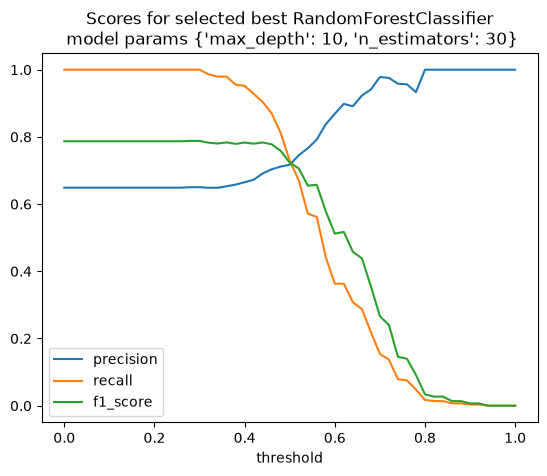

In [86]:
#try to find high precision score points
df_scores_rfc.plot.line(
    x="threshold",
    y=["precision", "recall", "f1_score"],
    title = f"Scores for selected best RandomForestClassifier\n model params {model_params_rfc}"
)
plt.show()

In [87]:
df_scores_rfc[(df_scores_rfc.threshold>0.4) & (df_scores_rfc.threshold<0.62)]

,threshold,tp,fp,fn,tn,precision,recall,accuracy,f1_score,tpr,fpr
21,0.42,271,132,21,26,0.672457,0.928082,0.660000,0.779856,0.928082,0.835443
22,0.44,264,118,28,40,0.691099,0.904110,0.675556,0.783383,0.904110,0.746835
23,0.46,254,107,38,51,0.703601,0.869863,0.677778,0.777948,0.869863,0.677215
24,0.48,237,96,55,62,0.711712,0.811644,0.664444,0.758400,0.811644,0.607595
25,0.50,213,84,79,74,0.717172,0.729452,0.637778,0.723260,0.729452,0.531646
26,0.52,196,67,96,91,0.745247,0.671233,0.637778,0.706306,0.671233,0.424051
27,0.54,167,51,125,107,0.766055,0.571918,0.608889,0.654902,0.571918,0.322785
28,0.56,164,43,128,115,0.792271,0.561644,0.620000,0.657315,0.561644,0.272152
29,0.58,129,25,163,133,0.837662,0.441781,0.582222,0.578475,0.441781,0.158228
30,0.60,106,16,186,142,0.868852,0.363014,0.551111,0.512077,0.363014,0.101266


In [88]:
df_scores_rfc[(df_scores_rfc.threshold>0.6) & (df_scores_rfc.threshold<0.82)]

,threshold,tp,fp,fn,tn,precision,recall,accuracy,f1_score,tpr,fpr
31,0.62,106,12,186,146,0.898305,0.363014,0.560000,0.517073,0.363014,0.075949
32,0.64,90,11,202,147,0.891089,0.308219,0.526667,0.458015,0.308219,0.069620
33,0.66,84,7,208,151,0.923077,0.287671,0.522222,0.438642,0.287671,0.044304
34,0.68,64,4,228,154,0.941176,0.219178,0.484444,0.355556,0.219178,0.025316
35,0.70,45,1,247,157,0.978261,0.154110,0.448889,0.266272,0.154110,0.006329
36,0.72,40,1,252,157,0.975610,0.136986,0.437778,0.240240,0.136986,0.006329
37,0.74,23,1,269,157,0.958333,0.078767,0.400000,0.145570,0.078767,0.006329
38,0.76,22,1,270,157,0.956522,0.075342,0.397778,0.139683,0.075342,0.006329
39,0.78,14,1,278,157,0.933333,0.047945,0.380000,0.091205,0.047945,0.006329
40,0.80,5,0,287,158,1.000000,0.017123,0.362222,0.033670,0.017123,0.000000


### Defining new rules after reviewing probabilities

#### Decision Tree Classifier

In [89]:
fmty_w_dms_prob = fmty_w_dms.copy()

In [ ]:
#get proba on entire dataset
y_pred_prob_all_dtc = dt_clf.predict_proba(x_all)
y_pred_prob_all_dtc_pos_class = [k[1] for k in y_pred_prob_all_dtc]
y_pred_prob_all_dtc_pos_class_arr = np.array(y_pred_prob_all_dtc_pos_class)

#define new rules from probabilities and thresholds
fmty_w_dms_prob["prob_4_dtc"] = y_pred_prob_all_dtc_pos_class_arr
fmty_w_dms_prob["rl_4_dtc_prob_42"] = (
    y_pred_prob_all_dtc_pos_class_arr > 0.42
).astype(int)

fmty_w_dms_prob["prob_dtc_5"] = y_pred_prob_all_dtc_pos_class_arr
fmty_w_dms_prob["rl_5_dtc_prob_62"] = (
    y_pred_prob_all_dtc_pos_class_arr > 0.62
).astype(int)

#### Random Forest Classifier

In [91]:
#get proba on entire dataset
y_pred_prob_all_rfc = rf_clf.predict_proba(x_all)
y_pred_prob_all_rfc_pos_class = [k[1] for k in y_pred_prob_all_rfc]
y_pred_prob_all_rfc_pos_class_arr = np.array(y_pred_prob_all_rfc_pos_class)

#define new rules from probabilities and thresholds
fmty_w_dms_prob["prob_rfc_6"] = y_pred_prob_all_rfc_pos_class_arr
fmty_w_dms_prob["rl_6_rfc_prob_4_6"] = (
    (y_pred_prob_all_rfc_pos_class_arr > 0.4) & (y_pred_prob_all_rfc_pos_class_arr < 0.62)
).astype(int)

fmty_w_dms_prob["prob_rfc_7"] = y_pred_prob_all_rfc_pos_class_arr
fmty_w_dms_prob["rl_7_rfc_prob_6_7"] = (
    (y_pred_prob_all_rfc_pos_class_arr > 0.6) & (y_pred_prob_all_rfc_pos_class_arr < 0.82)
).astype(int)

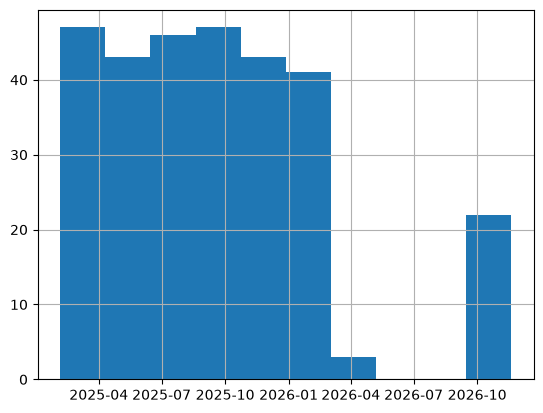

In [92]:
#when did it predict to trade for rl_4_dtc_prob_42
fmty_w_dms_prob[
    (fmty_w_dms_prob.split=="test") & (fmty_w_dms_prob.rl_4_dtc_prob_42==1)
].date.hist()
plt.show()

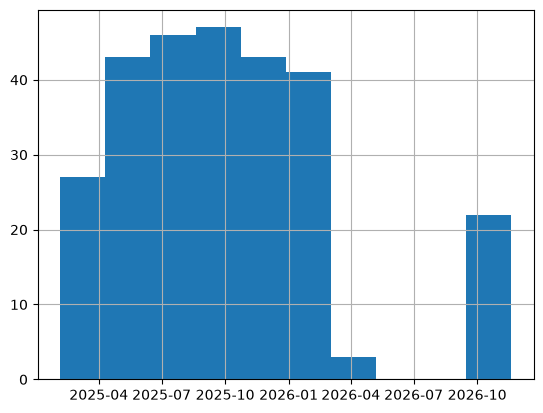

In [93]:
#when did it predict to trade for rl_5_dtc_prob_62
fmty_w_dms_prob[
    (fmty_w_dms_prob.split=="test") & (fmty_w_dms_prob.rl_5_dtc_prob_62==1)
].date.hist()
plt.show()

In [94]:
#sample of predictions with high threshold
fmty_w_dms_prob[
    (fmty_w_dms_prob.split=="test") & (fmty_w_dms_prob.rl_5_dtc_prob_62==1)
].sort_values(by="date").sample(5)

,Open,High,Low,Close,Volume,Dividends,date,growth_21_d,growth_42_d,growth_63_d,...,is_correct_2,is_correct_3,prob_4_dtc,rl_4_dtc_prob_42,prob_dtc_5,rl_5_dtc_prob_62,prob_rfc_6,rl_6_rfc_prob_4_6,prob_rfc_7,rl_7_rfc_prob_6_7
2729,13.009540,13.009540,12.721060,12.767590,1164027.0,0.000000,2025-10-21 00:00:00-06:00,1.011208,1.104997,1.129758,...,0,0,0.924357,1,0.924357,1,0.766223,0,0.766223,1
2812,14.568817,15.016356,14.540251,14.568817,4498169.0,0.000000,2026-02-20 00:00:00-06:00,0.963030,1.045005,0.962364,...,1,1,0.924357,1,0.924357,1,0.599240,1,0.599240,0
2604,10.744105,10.914078,10.744105,10.905131,935269.0,0.000000,2025-04-25 00:00:00-06:00,1.118898,1.097062,1.149682,...,0,0,0.924357,1,0.924357,1,0.499557,1,0.499557,0
2816,14.532581,14.762345,14.503860,14.609169,3189757.0,0.081398,2026-02-26 00:00:00-06:00,0.993601,1.016198,0.929798,...,1,1,0.924357,1,0.924357,1,0.663456,0,0.663456,1
2592,10.663589,10.869346,10.556237,10.833562,1097045.0,0.000000,2025-04-07 00:00:00-06:00,1.055585,1.130264,1.104176,...,0,0,0.924357,1,0.924357,1,0.565448,1,0.565448,0


In [95]:
#rules
RULES_PROB = [pred_name for pred_name in fmty_w_dms_prob.keys() if pred_name.startswith("rl")]
RULES_PROB

['rl_0_cci_63',
 'rl_1_cmo_63',
 'rl_2_cci_adosc_63',
 'rl_3_cmo_adosc_63',
 'rl_4_dtc_prob_42',
 'rl_5_dtc_prob_62',
 'rl_6_rfc_prob_4_6',
 'rl_7_rfc_prob_6_7']

In [96]:
#create column is_correct from each rule
for rule in RULES_PROB:
    prefix = rule.split("_")[1]
    fmty_w_dms_prob[f"is_correct_{prefix}"] = (
        fmty_w_dms_prob[rule] == fmty_w_dms_prob[TARGET]
    ).astype(int)

In [97]:
#list of is_correct names
IS_CORRECT_PROB = [name for name in fmty_w_dms_prob.keys() if name.startswith("is_correct")]
IS_CORRECT_PROB

['is_correct_0',
 'is_correct_1',
 'is_correct_2',
 'is_correct_3',
 'is_correct_4',
 'is_correct_5',
 'is_correct_6',
 'is_correct_7']

In [98]:
fmty_w_dms_prob[RULES_PROB].describe()

,rl_0_cci_63,rl_1_cmo_63,rl_2_cci_adosc_63,rl_3_cmo_adosc_63,rl_4_dtc_prob_42,rl_5_dtc_prob_62,rl_6_rfc_prob_4_6,rl_7_rfc_prob_6_7
count,2999.000000,2999.000000,2999.000000,2999.000000,2999.000000,2999.000000,2999.000000,2999.000000
mean,0.610203,0.978993,0.342447,0.171057,0.552518,0.527509,0.117039,0.068690
std,0.487785,0.143431,0.474608,0.376622,0.497317,0.499326,0.321520,0.252968
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000
75%,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000,0.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [99]:
fmty_w_dms_prob[IS_CORRECT_PROB].describe()

,is_correct_0,is_correct_1,is_correct_2,is_correct_3,is_correct_4,is_correct_5,is_correct_6,is_correct_7
count,2999.000000,2999.000000,2999.000000,2999.000000,2999.000000,2999.000000,2999.000000,2999.000000
mean,0.559186,0.623208,0.370790,0.352784,0.737579,0.728576,0.372124,0.411137
std,0.496567,0.484663,0.483097,0.477916,0.440024,0.444768,0.483452,0.492122
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000
75%,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [100]:
#code from module 3 notebook
for idx, col in enumerate(IS_CORRECT_PROB):
  #define precision for predictions on a test dataset
  rule = RULES_PROB[idx]
  rule_correct = col
  filter = ((fmty_w_dms_prob.split == "test") & (fmty_w_dms_prob[rule] == 1))

  print(f"rule:{rule}, rule_correct:{rule_correct}")
  print("Counts:",fmty_w_dms_prob[filter][rule_correct].value_counts())
  print("--")
  print("Ratio:",(fmty_w_dms_prob[filter][rule_correct].value_counts() / len(fmty_w_dms_prob[filter])).round(3))

  print("------")

rule:rl_0_cci_63, rule_correct:is_correct_0
Counts: is_correct_0
1    185
0    104
Name: count, dtype: int64
--
Ratio: is_correct_0
1    0.64
0    0.36
Name: count, dtype: float64
------
rule:rl_1_cmo_63, rule_correct:is_correct_1
Counts: is_correct_1
1    292
0    158
Name: count, dtype: int64
--
Ratio: is_correct_1
1    0.649
0    0.351
Name: count, dtype: float64
------
rule:rl_2_cci_adosc_63, rule_correct:is_correct_2
Counts: is_correct_2
0    90
1    53
Name: count, dtype: int64
--
Ratio: is_correct_2
0    0.629
1    0.371
Name: count, dtype: float64
------
rule:rl_3_cmo_adosc_63, rule_correct:is_correct_3
Counts: is_correct_3
0    62
1    18
Name: count, dtype: int64
--
Ratio: is_correct_3
0    0.775
1    0.225
Name: count, dtype: float64
------
rule:rl_4_dtc_prob_42, rule_correct:is_correct_4
Counts: is_correct_4
1    241
0     51
Name: count, dtype: int64
--
Ratio: is_correct_4
1    0.825
0    0.175
Name: count, dtype: float64
------
rule:rl_5_dtc_prob_62, rule_correct:is_corre

In [101]:
#precision
for rule in RULES_PROB:
    target = fmty_w_dms_prob[fmty_w_dms_prob["split"] == "test"][TARGET]
    pred = fmty_w_dms_prob[fmty_w_dms_prob["split"] == "test"][rule]

    tp = ((pred == 1) & (pred == target)).sum()
    fp = ((pred == 1) & (pred != target)).sum()

    #using tp, fp
    precision = tp / (tp + fp)

    print(f"\nRule:{rule} \nprecision (tp, fp):{np.round(precision, 3)}")
    #from precision_score
    #print("prec_score:", np.round(precision_score(target, pred), 3))


Rule:rl_0_cci_63 
precision (tp, fp):0.64

Rule:rl_1_cmo_63 
precision (tp, fp):0.649

Rule:rl_2_cci_adosc_63 
precision (tp, fp):0.371

Rule:rl_3_cmo_adosc_63 
precision (tp, fp):0.225

Rule:rl_4_dtc_prob_42 
precision (tp, fp):0.825

Rule:rl_5_dtc_prob_62 
precision (tp, fp):0.812

Rule:rl_6_rfc_prob_4_6 
precision (tp, fp):0.57

Rule:rl_7_rfc_prob_6_7 
precision (tp, fp):0.864


In [102]:
#rl_4: How many positive predictions per day?
rl_4_dly_pos_count = pd.DataFrame(
    fmty_w_dms_prob[
        (fmty_w_dms_prob.split=="test") & (fmty_w_dms_prob.rl_4_dtc_prob_42==1)
    ].groupby("date")["rl_4_dtc_prob_42"].count()
)

In [103]:
#rl_5: How many positive predictions per day?
rl_5_dly_pos_count = pd.DataFrame(
    fmty_w_dms_prob[
        (fmty_w_dms_prob.split=="test") & (fmty_w_dms_prob.rl_5_dtc_prob_62==1)
    ].groupby("date")["rl_5_dtc_prob_62"].count()
)

In [104]:
#rl_7: How many positive predictions per day?
rl_7_dly_pos_count = pd.DataFrame(
    fmty_w_dms_prob[
        (fmty_w_dms_prob.split=="test") & (fmty_w_dms_prob.rl_7_rfc_prob_6_7==1)
    ].groupby("date")["rl_7_rfc_prob_6_7"].count()
)

In [105]:
#unique trading days on test < 2 years (1.8)
fmty_w_dms_prob[(fmty_w_dms_prob.split=="test")].date.nunique()

450

In [106]:
rl_4_dly_pos_count

,rl_4_dtc_prob_42
date,
2025-02-04 00:00:00-06:00,1
2025-02-05 00:00:00-06:00,1
2025-02-06 00:00:00-06:00,1
2025-02-07 00:00:00-06:00,1
2025-02-10 00:00:00-06:00,1
...,...
2026-11-12 00:00:00-06:00,1
2026-11-13 00:00:00-06:00,1
2026-11-17 00:00:00-06:00,1


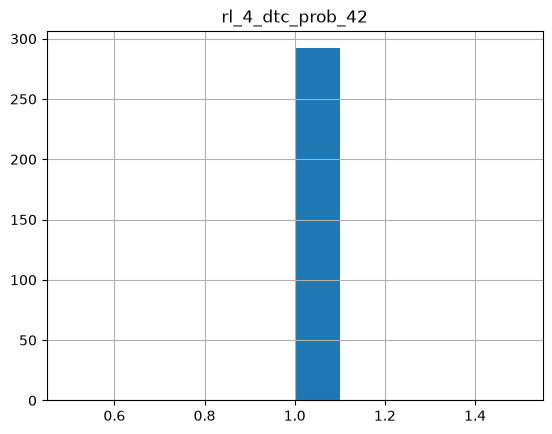

In [107]:
rl_4_dly_pos_count.hist()
plt.show()

In [108]:
rl_5_dly_pos_count

,rl_5_dtc_prob_62
date,
2025-02-04 00:00:00-06:00,1
2025-02-05 00:00:00-06:00,1
2025-02-06 00:00:00-06:00,1
2025-02-07 00:00:00-06:00,1
2025-02-10 00:00:00-06:00,1
...,...
2026-11-12 00:00:00-06:00,1
2026-11-13 00:00:00-06:00,1
2026-11-17 00:00:00-06:00,1


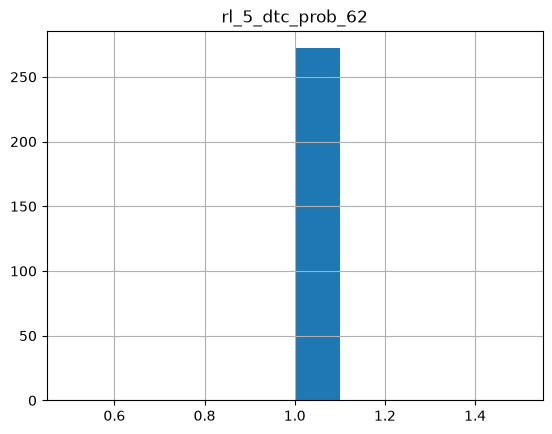

In [109]:
rl_5_dly_pos_count.hist()
plt.show()

In [110]:
rl_7_dly_pos_count

,rl_7_rfc_prob_6_7
date,
2025-02-05 00:00:00-06:00,1
2025-02-07 00:00:00-06:00,1
2025-02-10 00:00:00-06:00,1
2025-02-11 00:00:00-06:00,1
2025-02-13 00:00:00-06:00,1
...,...
2026-07-17 00:00:00-06:00,1
2026-07-20 00:00:00-06:00,1
2026-07-21 00:00:00-06:00,1


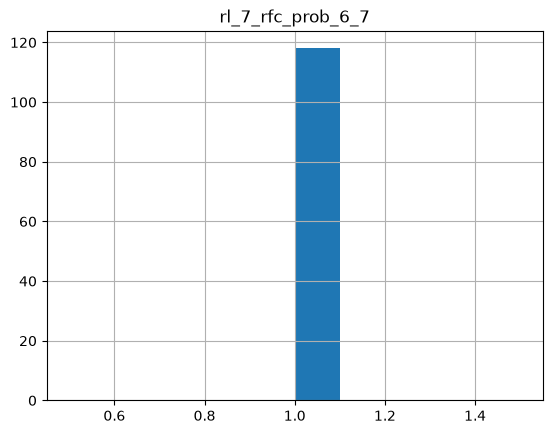

In [111]:
rl_7_dly_pos_count.hist()
plt.show()

In [112]:
print(rl_4_dly_pos_count.describe().T)
print(rl_5_dly_pos_count.describe().T)
print(rl_7_dly_pos_count.describe().T)

                  count  mean  std  min  25%  50%  75%  max
rl_4_dtc_prob_42  292.0   1.0  0.0  1.0  1.0  1.0  1.0  1.0
                  count  mean  std  min  25%  50%  75%  max
rl_5_dtc_prob_62  272.0   1.0  0.0  1.0  1.0  1.0  1.0  1.0
                   count  mean  std  min  25%  50%  75%  max
rl_7_rfc_prob_6_7  118.0   1.0  0.0  1.0  1.0  1.0  1.0  1.0


In [113]:
fmty_w_dms_prob.groupby("split")[RULES_PROB[4:]].agg(["count","sum","mean"]).T

split                          test        train         val
rl_4_dtc_prob_42  count  450.000000  2101.000000  448.000000
                  sum    292.000000  1320.000000   45.000000
                  mean     0.648889     0.628272    0.100446
rl_5_dtc_prob_62  count  450.000000  2101.000000  448.000000
                  sum    272.000000  1265.000000   45.000000
                  mean     0.604444     0.602094    0.100446
rl_6_rfc_prob_4_6 count  450.000000  2101.000000  448.000000
                  sum    298.000000    52.000000    1.000000
                  mean     0.662222     0.024750    0.002232
rl_7_rfc_prob_6_7 count  450.000000  2101.000000  448.000000
                  sum    118.000000    81.000000    7.000000
                  mean     0.262222     0.038553    0.015625

In [114]:
fmty_w_dms_prob.groupby("split")[RULES_PROB].agg(["count","sum","mean"]).T

split                          test        train         val
rl_0_cci_63       count  450.000000  2101.000000  448.000000
                  sum    289.000000  1313.000000  228.000000
                  mean     0.642222     0.624941    0.508929
rl_1_cmo_63       count  450.000000  2101.000000  448.000000
                  sum    450.000000  2038.000000  448.000000
                  mean     1.000000     0.970014    1.000000
rl_2_cci_adosc_63 count  450.000000  2101.000000  448.000000
                  sum    143.000000   794.000000   90.000000
                  mean     0.317778     0.377915    0.200893
rl_3_cmo_adosc_63 count  450.000000  2101.000000  448.000000
                  sum     80.000000   390.000000   43.000000
                  mean     0.177778     0.185626    0.095982
rl_4_dtc_prob_42  count  450.000000  2101.000000  448.000000
                  sum    292.000000  1320.000000   45.000000
                  mean     0.648889     0.628272    0.100446
rl_5_dtc_prob_62  count  450.000000  2101.000000  448.000000
                  sum    272.000000  1265.000000   45.000000
                  mean     0.604444     0.602094    0.100446
rl_6_rfc_prob_4_6 count  450.000000  2101.000000  448.000000
                  sum    298.000000    52.000000    1.000000
                  mean     0.662222     0.024750    0.002232
rl_7_rfc_prob_6_7 count  450.000000  2101.000000  448.000000
                  sum    118.000000    81.000000    7.000000
                  mean     0.262222     0.038553    0.015625

### Trading simulations

In [115]:
current_pred = "rl_4_dtc_prob_42"
#compare the predictions from current_pred to TARGET
fmty_w_dms_prob[["growth_63_d", TARGET, current_pred]].sample(10)

,growth_63_d,is_growth_63,rl_4_dtc_prob_42
2329,0.890892,0,0
1387,0.998299,0,1
2754,1.057021,1,1
1562,1.059375,1,1
16,1.074380,1,1
1615,1.061576,1,1
1422,1.085678,1,1
1323,0.955880,0,1
2777,1.006545,1,1
781,0.976688,0,0


In [116]:
#the amount invested starts in 20 mxn min 1 buy, reasonable to start
DLY_INVST_AMT = 20
#0.25%
FEE = 0.0025
#IVA 16%, calculated on the fee amount obtained e.g. (100 * 0.0025) -> this is the fee amount
IVA = 0.16
#gross revenue
fmty_w_dms_prob["sim_1_rl_4_gross_rev"] = fmty_w_dms_prob[current_pred] * DLY_INVST_AMT * (fmty_w_dms_prob["growth_63_d"] - 1)
#fees: 0.25% for the amount of the operation
fmty_w_dms_prob["sim_1_rl_4_fee"] = -fmty_w_dms_prob[current_pred] * DLY_INVST_AMT * FEE
#iva: 16% applied on the fee
fmty_w_dms_prob["sim_1_rl_4_iva"] = fmty_w_dms_prob["sim_1_rl_4_fee"] * IVA
#net revenue: gross revenue + fee + iva
fmty_w_dms_prob["sim_1_rl_4_net_rev"] = fmty_w_dms_prob["sim_1_rl_4_gross_rev"] + fmty_w_dms_prob["sim_1_rl_4_fee"] + fmty_w_dms_prob["sim_1_rl_4_iva"]

In [117]:
#sample results
FIN_RSLT_RL_4 = ["date","Close"] + ["growth_63_d", TARGET] + [current_pred, "sim_1_rl_4_gross_rev", "sim_1_rl_4_fee", "sim_1_rl_4_iva", "sim_1_rl_4_net_rev"]
fmty_w_dms_prob[
    (fmty_w_dms_prob.split=="test") & (fmty_w_dms_prob[current_pred]==1) & (fmty_w_dms_prob["growth_63_d"].notna())
][FIN_RSLT_RL_4].sample(10)

,date,Close,growth_63_d,is_growth_63,rl_4_dtc_prob_42,sim_1_rl_4_gross_rev,sim_1_rl_4_fee,sim_1_rl_4_iva,sim_1_rl_4_net_rev
2658,2025-07-11 00:00:00-06:00,11.998683,1.070287,1,1,1.405745,-0.05,-0.008,1.347745
2590,2025-04-03 00:00:00-06:00,10.940915,1.082492,1,1,1.649835,-0.05,-0.008,1.591835
2783,2026-01-09 00:00:00-06:00,14.888359,1.027141,1,1,0.542824,-0.05,-0.008,0.484824
2581,2025-03-21 00:00:00-06:00,10.600967,1.118272,1,1,2.365433,-0.05,-0.008,2.307433
2701,2025-09-10 00:00:00-06:00,13.079638,1.101675,1,1,2.033509,-0.05,-0.008,1.975509
2635,2025-06-10 00:00:00-06:00,12.226639,1.017563,1,1,0.351269,-0.05,-0.008,0.293269
2693,2025-08-29 00:00:00-06:00,12.256379,1.102675,1,1,2.053508,-0.05,-0.008,1.995508
2735,2025-10-29 00:00:00-06:00,12.963012,1.093024,1,1,1.860489,-0.05,-0.008,1.802489
2686,2025-08-20 00:00:00-06:00,12.039468,1.077807,1,1,1.556142,-0.05,-0.008,1.498142
2676,2025-08-06 00:00:00-06:00,12.342752,1.061943,1,1,1.238856,-0.05,-0.008,1.180856


In [118]:
#daily investments, expect 1 from what I saw in pos count hist plots
pos_current_pred = (fmty_w_dms_prob.split=="test") & (fmty_w_dms_prob[current_pred]==1) & (fmty_w_dms_prob["growth_63_d"].notna())
inv_count_daily_df = pd.DataFrame(
    fmty_w_dms_prob[pos_current_pred].groupby("date")[current_pred].count()
)
#75% case how many investments per day?
sim_1_rl_4_avg_inv_day = inv_count_daily_df[current_pred].quantile(0.75)
print("avg trade per day:",sim_1_rl_4_avg_inv_day)

avg trade per day: 1.0


In [119]:
#how many times do you invest daily?
inv_count_daily_df.describe().T

,count,mean,std,min,25%,50%,75%,max
rl_4_dtc_prob_42,270.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0


In [120]:
#totals
fmty_w_dms_prob[
    (fmty_w_dms_prob.split=="test") & (fmty_w_dms_prob[current_pred]==1) & (fmty_w_dms_prob["growth_63_d"].notna())
][["sim_1_rl_4_gross_rev", "sim_1_rl_4_fee", "sim_1_rl_4_iva", "sim_1_rl_4_net_rev"]].sum()

sim_1_rl_4_gross_rev    457.977925
sim_1_rl_4_fee          -13.500000
sim_1_rl_4_iva           -2.160000
sim_1_rl_4_net_rev      442.317925
dtype: float64

#### Simplified and approximate calculations

In [121]:
RULES_PROB

['rl_0_cci_63',
 'rl_1_cmo_63',
 'rl_2_cci_adosc_63',
 'rl_3_cmo_adosc_63',
 'rl_4_dtc_prob_42',
 'rl_5_dtc_prob_62',
 'rl_6_rfc_prob_4_6',
 'rl_7_rfc_prob_6_7']

In [122]:
#target and source of target
TARGET_SRC = "growth_63_d"
TARGET = "is_growth_63"
#trading days
TRADING_DAYS = 21
#years for CAGR
YEARS_CAGR = 2
#the amount invested starts in 20 mxn min 1 buy, reasonable to start
DLY_INVST_AMT = 20
#0.25%
FEE = 0.0025
#IVA 16%, calculated on the fee amount obtained e.g. (100 * 0.0025) -> this is the fee amount
IVA = 0.16
#store result here
sim_1_rslts = []

#results for rules (manual/models)
for rule in RULES_PROB:
  print(f"Simulation for rule: {rule} in progress ...")
  test_rule_count = len(fmty_w_dms_prob[
    (fmty_w_dms_prob.split=="test") & (fmty_w_dms_prob[rule]==1) & (fmty_w_dms_prob[TARGET_SRC].notna())
  ])
  test_count = len(fmty_w_dms_prob[(fmty_w_dms_prob.split=="test")])  
  print(f"Count times of investment {test_rule_count} out of {test_count} TEST records")

  #rule prefixes rl_1, rl_2 ... rl_n
  name = rule.split("_")[0:2]
  rl_prefix = "_".join(name)

  #agg results
  fmty_w_dms_prob["sim_1_"+rl_prefix+"_gross_rev"] = fmty_w_dms_prob[rule] * DLY_INVST_AMT * (fmty_w_dms_prob[TARGET_SRC] - 1)
  fmty_w_dms_prob["sim_1_"+rl_prefix+"_fee"] = -fmty_w_dms_prob[rule] * DLY_INVST_AMT * FEE
  fmty_w_dms_prob["sim_1_"+rl_prefix+"_iva"] = fmty_w_dms_prob["sim_1_"+rl_prefix+"_fee"] * IVA
  fmty_w_dms_prob["sim_1_"+rl_prefix+"_net_rev"] = fmty_w_dms_prob["sim_1_"+rl_prefix+"_gross_rev"] + fmty_w_dms_prob["sim_1_"+rl_prefix+"_fee"] + fmty_w_dms_prob["sim_1_"+rl_prefix+"_iva"]

  #use test observations where rule is true
  test_rule_pos = (fmty_w_dms_prob.split=="test") & (fmty_w_dms_prob[rule]==1) & (fmty_w_dms_prob[TARGET_SRC].notna())
  #count number of investments
  inv_count = len(fmty_w_dms_prob[test_rule_pos])
  #get rule totals where rule is true in each agg result
  total_gross_rev = fmty_w_dms_prob[test_rule_pos]["sim_1_"+rl_prefix+"_gross_rev"].sum()
  total_fees = fmty_w_dms_prob[test_rule_pos]["sim_1_"+rl_prefix+"_fee"].sum()
  total_iva = fmty_w_dms_prob[test_rule_pos]["sim_1_"+rl_prefix+"_iva"].sum()
  total_net_rev = fmty_w_dms_prob[test_rule_pos]["sim_1_"+rl_prefix+"_net_rev"].sum()

  #get total fees when gross_rev is ot negligible to data scale
  scale = fmty_w_dms_prob["sim_1_"+rl_prefix+"_net_rev"].abs().max()
  #10 orders of magnitude below the largest value
  threshold = 1e-10 * scale
  if abs(total_net_rev) > threshold:
    fees_percentage = -(total_fees + total_iva) / total_net_rev
  else:
    fees_percentage = None

  #get net revenue when investment were made
  if inv_count > 0:
    avg_net_rev = total_net_rev / inv_count
  else:
    avg_net_rev = None

  #approx capital required and CAGR Calculation
  inv_count_dly_df = pd.DataFrame(fmty_w_dms_prob[test_rule_pos].groupby("date")[rule].count())
  avg_inv_per_day = inv_count_dly_df[rule].mean()
  #75% case how many investments per day?
  p_75_inv_per_day = inv_count_dly_df[rule].quantile(0.75)
  #inv_count_dly_df[rule].mean()
  #21 (trading) days in a row with positive rule
  inv_capital = DLY_INVST_AMT * TRADING_DAYS * p_75_inv_per_day
  #remember past performance does not guarantee future results
  #cagr here is only an estimation in n=2 (~ 2 years, 1.8 real)
  estimation_cagr = ((inv_capital + total_net_rev)/inv_capital)**(1/YEARS_CAGR)

  # append to DF
  sim_1_rslts.append(
    (rule, inv_count, total_gross_rev, total_fees, total_iva, total_net_rev,
      fees_percentage, avg_net_rev, avg_inv_per_day, inv_capital, estimation_cagr)
  )

  #output for all rules with positive predictions
  columns = [
    "sim_1_"+rl_prefix+"_gross_rev", "sim_1_"+rl_prefix+"_fee",
    "sim_1_"+rl_prefix+"_iva", "sim_1_"+rl_prefix+"_net_rev"
  ]

  if inv_count > 1:
    print(f"Financial Result:\n{fmty_w_dms_prob[test_rule_pos][columns].sum()}")
    print("--[Rounding to 3 decimals only for display purposes]--")
    print(f"  Count Investments in {YEARS_CAGR} years (on TEST): {inv_count}")
    print(f"  Gross Revenue: MX${np.round(total_gross_rev, 3)}")
    print(f"  Fees (0.25% for buy+sell): MX${-np.round(total_fees, 3)}")
    print(f"  IVA (16% on Fee): MX${-np.round(total_iva, 3)}")
    print(f"  Net Revenue: MX${np.round(total_net_rev, 3)}")
    print(f"  Fees are {-np.round(100.0 * (total_fees + total_iva) / total_gross_rev, 3)}% of Gross Revenue")
    print(f"  Capital Required : MX${inv_capital} (Vbegin)")
    print(f"  Final value (Vbegin + Net_revenue) : MX${np.round(inv_capital + total_net_rev, 3)} (Vfinal)\n")

    print(f"Average CAGR on TEST ({YEARS_CAGR} years): {np.round(estimation_cagr, 3)}, or {np.round(100.0 * (estimation_cagr - 1), 1)}%")
    print("Average daily stats:")
    print(f"  Average net revenue per investment: MX${total_net_rev / inv_count}")
    print(f"  Average investments per day: {int(np.round(avg_inv_per_day))}")
    print(f"  Q75 investments per day: {int(np.round(p_75_inv_per_day))}")
    print("=============================================")


#select columns to build df
columns_simulation = [
  "rule", "inv_count", "total_gross_rev", "total_fees", "total_iva", "total_net_rev",
  "fees_percentage", "avg_net_rev", "avg_inv_per_day", "inv_capital", "estimation_cagr"
]

sim_1_rslts_df = pd.DataFrame(sim_1_rslts, columns=columns_simulation)

Simulation for rule: rl_0_cci_63 in progress ...
Count times of investment 245 out of 450 TEST records
Financial Result:
sim_1_rl_0_gross_rev    297.811624
sim_1_rl_0_fee          -12.250000
sim_1_rl_0_iva           -1.960000
sim_1_rl_0_net_rev      283.601624
dtype: float64
--[Rounding to 3 decimals only for display purposes]--
  Count Investments in 2 years (on TEST): 245
  Gross Revenue: MX$297.812
  Fees (0.25% for buy+sell): MX$12.25
  IVA (16% on Fee): MX$1.96
  Net Revenue: MX$283.602
  Fees are 4.771% of Gross Revenue
  Capital Required : MX$420.0 (Vbegin)
  Final value (Vbegin + Net_revenue) : MX$703.602 (Vfinal)

Average CAGR on TEST (2 years): 1.294, or 29.4%
Average daily stats:
  Average net revenue per investment: MX$1.157557650292132
  Average investments per day: 1
  Q75 investments per day: 1
Simulation for rule: rl_1_cmo_63 in progress ...
Count times of investment 387 out of 450 TEST records
Financial Result:
sim_1_rl_1_gross_rev    476.90393
sim_1_rl_1_fee          

In [123]:
print(sim_1_rslts_df.head(10))

                rule  inv_count  total_gross_rev  total_fees  total_iva  \
0        rl_0_cci_63        245       297.811624      -12.25     -1.960   
1        rl_1_cmo_63        387       476.903930      -19.35     -3.096   
2  rl_2_cci_adosc_63         99        52.198559       -4.95     -0.792   
3  rl_3_cmo_adosc_63         52        24.783854       -2.60     -0.416   
4   rl_4_dtc_prob_42        270       457.977925      -13.50     -2.160   
5   rl_5_dtc_prob_62        250       391.153178      -12.50     -2.000   
6  rl_6_rfc_prob_4_6        243       216.891256      -12.15     -1.944   
7  rl_7_rfc_prob_6_7        117       227.858265       -5.85     -0.936   

   total_net_rev  fees_percentage  avg_net_rev  avg_inv_per_day  inv_capital  \
0     283.601624         0.050105     1.157558              1.0        420.0   
1     454.457930         0.049391     1.174310              1.0        420.0   
2      46.456559         0.123599     0.469258              1.0        420.0   
3   

In [130]:
sim_1_rslts_df["sim_1_growth_capital_2y"] = (sim_1_rslts_df.total_net_rev + sim_1_rslts_df.inv_capital) / sim_1_rslts_df.inv_capital

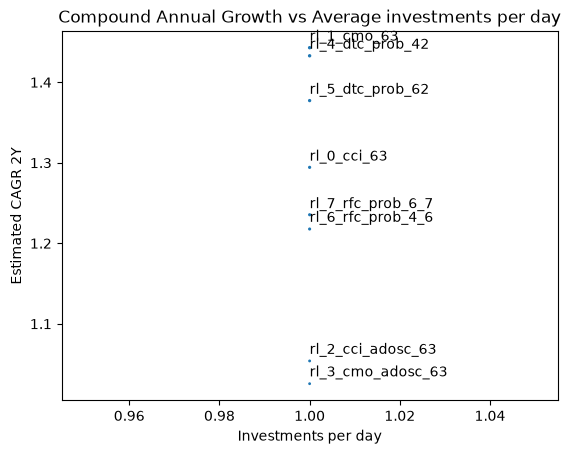

In [140]:
#scatter plot
fig = plt.scatter(
    x=sim_1_rslts_df.avg_inv_per_day,
    y=sim_1_rslts_df.estimation_cagr,
    s=sim_1_rslts_df.sim_1_growth_capital_2y,
)
plt.title("Compound Annual Growth vs Average investments per day")
plt.xlabel("Investments per day")
plt.ylabel("Estimated CAGR 2Y")

for i, txt in enumerate(sim_1_rslts_df.rule.values):
    plt.annotate(
        txt, (
            np.round(sim_1_rslts_df.avg_inv_per_day[i], 3), np.round(sim_1_rslts_df.estimation_cagr[i], 3)
        ),
        xytext=(0, 5),
        textcoords="offset points",
        fontsize=10,
        ha="left"
    )

plt.show()